# 強化学習で囚人のジレンマの戦略を作る

戦略大会では，皆さんが自分で考えた戦略が対戦しました。では，戦略を人間が考えるのではなく，**コンピュータに対戦をくり返させて，自分で学ばせる**ことはできるでしょうか。これが強化学習（reinforcement learning）の考え方です。囲碁の AlphaGo や，ロボットの制御，そして ChatGPT などの対話 AI の調整にも，強化学習が使われています。

## 強化学習の枠組み

強化学習では，次のように考えます。

* **エージェント**（学習する側）が，**状態** $s$ を見て，**行動** $a$ を選ぶ。
* **環境**（相手）が反応し，エージェントは**報酬** $r$ を受け取り，次の状態 $s'$ に移る。
* これをくり返して，将来にわたる報酬の合計が大きくなるような行動の選び方（**方策**）を学ぶ。

囚人のジレンマでは，エージェントが自分の戦略，環境が相手の戦略，行動が C か D，報酬がその回の得点です。状態としては，例えば「直近 K 回の，自分と相手の手」を使うことにします。

次の状態が，今の状態と行動だけで（確率的に）決まる時，これを**マルコフ決定過程**（MDP）といいます。

**バンディット問題との関係**：第10回の多腕バンディット問題は，状態が1つしかない（スロットを引いても状況が変わらない）強化学習の問題です。「今一番よさそうなスロットを引く（活用）」か「他のスロットも試す（探索）」かのかねあいは，強化学習でも同じように現れます。

## Q 値と Q 学習

状態 $s$ で行動 $a$ をとり，その後は最善の行動をとり続けた時の，将来の報酬の合計の期待値を $Q(s, a)$ と書きます（Q 値）。Q 値が分かれば，各状態で Q 値の大きい方の行動を選べばよいことになります。

Q 値は，次の関係（ベルマン方程式）を満たします。
$$
Q(s, a) = E\left[\, r + \gamma \max_{a'} Q(s', a') \,\right]
$$
$\gamma$ は割引率で，将来の報酬をどれだけ重く見るかを表します。囚人のジレンマの大会では，毎回 1% の確率で対戦が終わるので，次の回の報酬は「続いていれば」もらえるものです。そこで，$\gamma = 0.99$ とするのが自然です。

**Q 学習**は，実際に対戦しながら，この関係に近づくように Q 値を少しずつ修正していく方法です。状態 $s$ で行動 $a$ をとって，報酬 $r$ をもらい，状態 $s'$ に移ったら，
$$
Q(s, a) \leftarrow Q(s, a) + \alpha \left( r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right)
$$
と更新します。$\alpha$ は学習率（どれだけ修正するか）です。学習中は，確率 $\varepsilon$ でランダムな行動をとって探索します（$\varepsilon$-greedy）。

## プログラム

`MakeQStrategy(K, rate)` は，直近 K 回の手を状態とする Q 学習の戦略クラスを作る関数です。rate=True なら，相手がこれまでに協調した割合（5段階）も状態に加えます。Q 値は，クラス変数 Q に辞書として保存するので，対戦をまたいで学習結果が残ります。

`Train(S, n)` は，戦略 S を，主催者の戦略からランダムに選んだ相手と n 回対戦させて学習させます。学習が終わると，S は Q 値の大きい方の手を出す（乱数を使わない）戦略になります。

In [1]:
from pd import *
import random

def MakeQStrategy(K, rate=False):
    ''' 直近 K 回の手（と，rate=True なら相手の協調率）を状態とする Q 学習の戦略クラスを作る '''
    class QStrategy:
        Q = {}              # Q[状態] = {'C': 値, 'D': 値}（クラス変数なので，対戦をまたいで残る）
        train = False       # True の時だけ学習する
        eps = 0.1           # 探索（ランダムな手を出す）確率
        alpha = 0.05        # 学習率
        gamma = 1 - PEND    # 割引率

        def __init__(self):
            self.h = []     # 'CD' のような「自分の手+相手の手」の文字列のリスト
            self.nc = 0     # 相手が協調した回数
            self.s = self.state()

        def state(self):
            w = ['--'] * (K - len(self.h)) + self.h[-K:]
            if rate:
                n = len(self.h)
                w.append('?' if n < 10 else min(int(5 * self.nc / n), 4))
            return tuple(w)

        def q(self, s):
            return QStrategy.Q.setdefault(s, {'C': 0.0, 'D': 0.0})

        def choice(self):
            if QStrategy.train and random.uniform(0, 1) < QStrategy.eps:
                return random.choice('CD')
            v = self.q(self.s)
            return 'C' if v['C'] >= v['D'] else 'D'

        def learn(self, my, other):
            s = self.s
            self.h.append(my + other)
            if other == 'C':
                self.nc += 1
            self.s = self.state()
            if QStrategy.train:
                r = PAYOFF[(my, other)]
                v = self.q(s)
                v[my] += QStrategy.alpha * (r + QStrategy.gamma * max(self.q(self.s).values()) - v[my])

    QStrategy.__name__ = f'Q{K}' + ('rate' if rate else '')
    return QStrategy


def Train(S, n, seed=0):
    ''' 戦略 S を，主催者の戦略からランダムに選んだ相手と n 回対戦させて学習させる '''
    rng = random.Random(seed)
    S.train = True
    for e in range(n):
        S.alpha = 0.05 * (1 - e / n) + 0.001    # 学習率をだんだん小さくする
        Match(S, rng.choice(HOUSE), seed=10**8 + 10**6 * seed + e)
    S.train = False


## 直近1回の手だけを見る場合

K = 1 とすると，状態は「最初」と，前の回の (自分, 相手) の手 CC, CD, DC, DD の5通りしかありません。学習した結果の方策を表示してみましょう。乱数の種を変えて3回学習させます。

In [2]:
for sd in range(3):
    S = MakeQStrategy(1)
    Train(S, 20000, seed=sd)
    policy = {s[0]: ('C' if v['C'] >= v['D'] else 'D') for s, v in sorted(S.Q.items())}
    res, total = Evaluate(S, show=False)
    print(policy, f'平均 {total:.3f}')

{'--': 'C', 'CC': 'C', 'CD': 'D', 'DC': 'C', 'DD': 'D'} 平均 2.352


{'--': 'C', 'CC': 'D', 'CD': 'C', 'DC': 'C', 'DD': 'C'} 平均 2.135


{'--': 'D', 'CC': 'C', 'CD': 'D', 'DC': 'D', 'DD': 'C'} 平均 2.301


**考えよう**：学習した方策を，主催者の戦略と比べてみよう。しっぺ返し（相手の前の手をまねる）は，CC→C, CD→D, DC→C, DD→D です。Pavlov（得点が 3 か 5 なら同じ手，0 か 1 なら手を変える）は，CC→C, CD→D, DC→D, DD→C です。

誰にも教わらずに，しっぺ返し（1回目）や Pavlov（3回目，ただし最初の手は D）を「再発見」しています。2回目のように，あまりよくない戦略に落ち着くこともあります。学習するたびに結果が変わるのは，これらの戦略の価値の差がとても小さく，わずかな乱数の違いでどれに落ち着くかが変わるからです（次のセルで Q 値を見てみよう）。

In [3]:
S1 = MakeQStrategy(1)
Train(S1, 20000, seed=0)
for s, v in sorted(S1.Q.items()):
    print(s, {a: round(x, 1) for a, x in v.items()})

('--',) {'C': 233.9, 'D': 231.1}
('CC',) {'C': 234.6, 'D': 233.9}
('CD',) {'C': 233.0, 'D': 233.7}
('DC',) {'C': 232.0, 'D': 231.9}
('DD',) {'C': 232.0, 'D': 232.2}


Q 値はどれも 230 前後です。1回あたり平均約 2.3 点を，平均 $1/(1-\gamma) = 100$ 回もらうことに対応しています。C と D の差は，それに比べてとても小さいことが分かります。

## 見る範囲を広げる

K = 2, 3 として学習させ，主催者の戦略に対する得点を比べよう。

In [4]:
Q2 = MakeQStrategy(2)
Train(Q2, 50000)
Q3 = MakeQStrategy(3)
Train(Q3, 50000)
for S in [TitForTat, GenerousTFT, Q2, Q3]:
    res, total = Evaluate(S, show=False)
    print(f'{S.__name__:>12s} : 平均 {total:.3f}  対戦点 {Points(total)}')

   TitForTat : 平均 2.352  対戦点 6.0
 GenerousTFT : 平均 2.394  対戦点 6.8


          Q2 : 平均 2.324  対戦点 5.4
          Q3 : 平均 2.501  対戦点 9.0


直近3回の手を見ると，しっぺ返しや寛容なしっぺ返しよりも強くなりました。相手ごとの得点を見てみましょう。

In [5]:
Q2r = MakeQStrategy(2, rate=True)
Train(Q2r, 50000)
rows = [TitForTat, Q3, Q2r]
table = {S.__name__: Evaluate(S, show=False)[0] for S in rows}
print(' ' * 14 + ''.join(f'{S.__name__:>9s}' for S in rows))
for B in HOUSE:
    print(f'{B.__name__:>14s}' + ''.join(f'{table[S.__name__][B.__name__]:9.3f}' for S in rows))
for S in rows:
    res, total = Evaluate(S, show=False)
    print(f'{S.__name__:>8s} : 平均 {total:.3f}  対戦点 {Points(total)}')

              TitForTat       Q3   Q2rate
          AllC    3.013    3.436    3.663
          AllD    0.985    0.711    0.881
       RandomS    2.217    2.227    2.288
     Alternate    2.471    2.461    2.626
     TitForTat    2.591    2.744    2.795
 SuspiciousTFT    2.271    2.609    2.675
   GenerousTFT    2.952    2.963    2.963
 TitForTwoTats    3.014    3.376    3.646
          Grim    1.913    1.786    1.483
        Pavlov    2.519    2.853    2.568
          Joss    1.931    2.345    2.564
TitForTat : 平均 2.352  対戦点 6.0


      Q3 : 平均 2.501  対戦点 9.0
  Q2rate : 平均 2.559  対戦点 10.0


Q3 は，AllC や TitForTwoTats のような寛容な相手から多く得点し，TitForTat, SuspiciousTFT, Joss とは報復の連鎖を抜け出すことで，しっぺ返しより得点を上げています。一方で，AllD（いつも裏切り）や Grim（一度裏切られたらずっと裏切る）に対しては，しっぺ返しより弱くなっています。

直近3回だけを見ていると，「相手がずっと裏切り続ける状態なのか」「ノイズでたまたま裏切りが続いたのか」を区別できません。相手がどういう戦略かは，もっと長い履歴にしか現れないからです。直近 K 回の手は，本当はマルコフ性をもつ「状態」になっていません（相手の中身が見えないので，部分観測マルコフ決定過程（POMDP）と呼ばれる問題になっています）。

そこで，相手のこれまでの協調率を状態に加えた Q2rate では，AllD への対応がよくなり，全体の得点も上がりました。ただし，Grim に対してはかえって弱くなっています。寛容な相手から搾取しようと裏切ると，Grim は二度と協調しなくなるからです。搾取をねらうと，報復する相手には損をするというかねあいがあります。**何を状態にするか**が，強化学習の性能を大きく左右します。

## 学習の進み方

Q2rate について，学習させる対戦の回数を変えて，得点がどう変わるかを見てみよう。

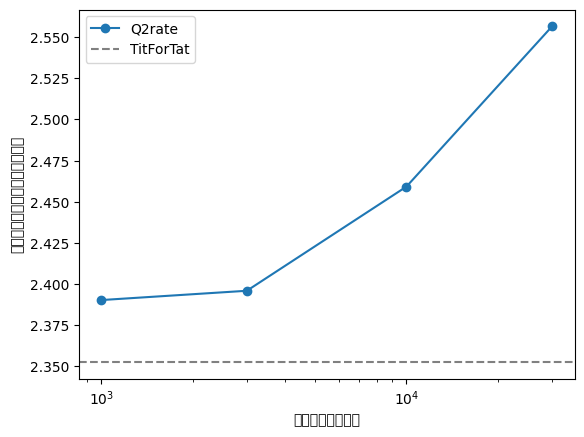

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
import platform
if platform.system() == "Darwin":      # Mac
    plt.rcParams["font.family"] = "Hiragino Sans"
elif platform.system() == "Windows":
    plt.rcParams["font.family"] = "Yu Gothic"

ns = [1000, 3000, 10000, 30000]
sc = []
for n in ns:
    S = MakeQStrategy(2, rate=True)
    Train(S, n)
    sc.append(Evaluate(S, show=False)[1])
base = Evaluate(TitForTat, show=False)[1]
plt.semilogx(ns, sc, 'o-', label='Q2rate')
plt.axhline(base, color='gray', linestyle='--', label='TitForTat')
plt.xlabel('学習した対戦の数')
plt.ylabel('主催者の戦略に対する平均得点')
plt.legend()
plt.show()

## 考えよう

1. 学習した戦略は，主催者の戦略を相手にして学習したものです。皆さんの戦略が相手の大会でも強いでしょうか。主催者の戦略に特化しすぎる（**過学習**）と，どうなるでしょうか。大会の結果で確かめよう。
2. 相手も学習する戦略だったらどうなるでしょうか。相手が変化するので，自分から見た環境は一定ではなくなります。第10回の change=True の問題と比べてみよう。
3. 学習した戦略は，乱数を使わない戦略になっています。相手の戦略が決まっている時，一番よい戦略は乱数を使わずに作れることが知られています（各時点で C を出す確率を $q$ とすると，期待得点は $q$ の1次式なので，$q = 0$ か $1$ で最大になる）。
4. 皆さんが大会で作った戦略と比べて，強化学習の戦略は強かったでしょうか。人間が考えた戦略の方がよいところはどこでしょうか。